<a href="https://colab.research.google.com/github/Uzma2147/Hospital_Readdmission/blob/main/Hospital_Readdmision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
#Step 1: Data Ingestion & Workspace Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# Set visual styling for charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset
df = pd.read_csv('hospital_readmissions.csv')

# Display dataset dimensions and initial preview
print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 25,000 rows, 17 columns


,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted
0,[70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,no,yes,no
1,[70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,no,yes,no
2,[50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,yes,yes,yes
3,[70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes
4,[60-70),1,42,0,7,0,0,0,InternalMedicine,Other,Circulatory,Respiratory,no,no,no,yes,no


In [69]:
#Step 2: Data Quality & Profiling
# 1. Check for missing values
print("=== MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())

# 2. Check for duplicate rows
print(f"\nTotal Duplicate Rows: {df.duplicated().sum()}")

# 3. Inspect Target Class Distribution
print("\n=== TARGET CLASS DISTRIBUTION (readmitted) ===")
print(df['readmitted'].value_counts())
print(df['readmitted'].value_counts(normalize=True) * 100)

=== MISSING VALUES PER COLUMN ===
age                  0
time_in_hospital     0
n_lab_procedures     0
n_procedures         0
n_medications        0
n_outpatient         0
n_inpatient          0
n_emergency          0
medical_specialty    0
diag_1               0
diag_2               0
diag_3               0
glucose_test         0
A1Ctest              0
change               0
diabetes_med         0
readmitted           0
dtype: int64

Total Duplicate Rows: 0

=== TARGET CLASS DISTRIBUTION (readmitted) ===
readmitted
no     13246
yes    11754
Name: count, dtype: int64
readmitted
no     52.984
yes    47.016
Name: proportion, dtype: float64


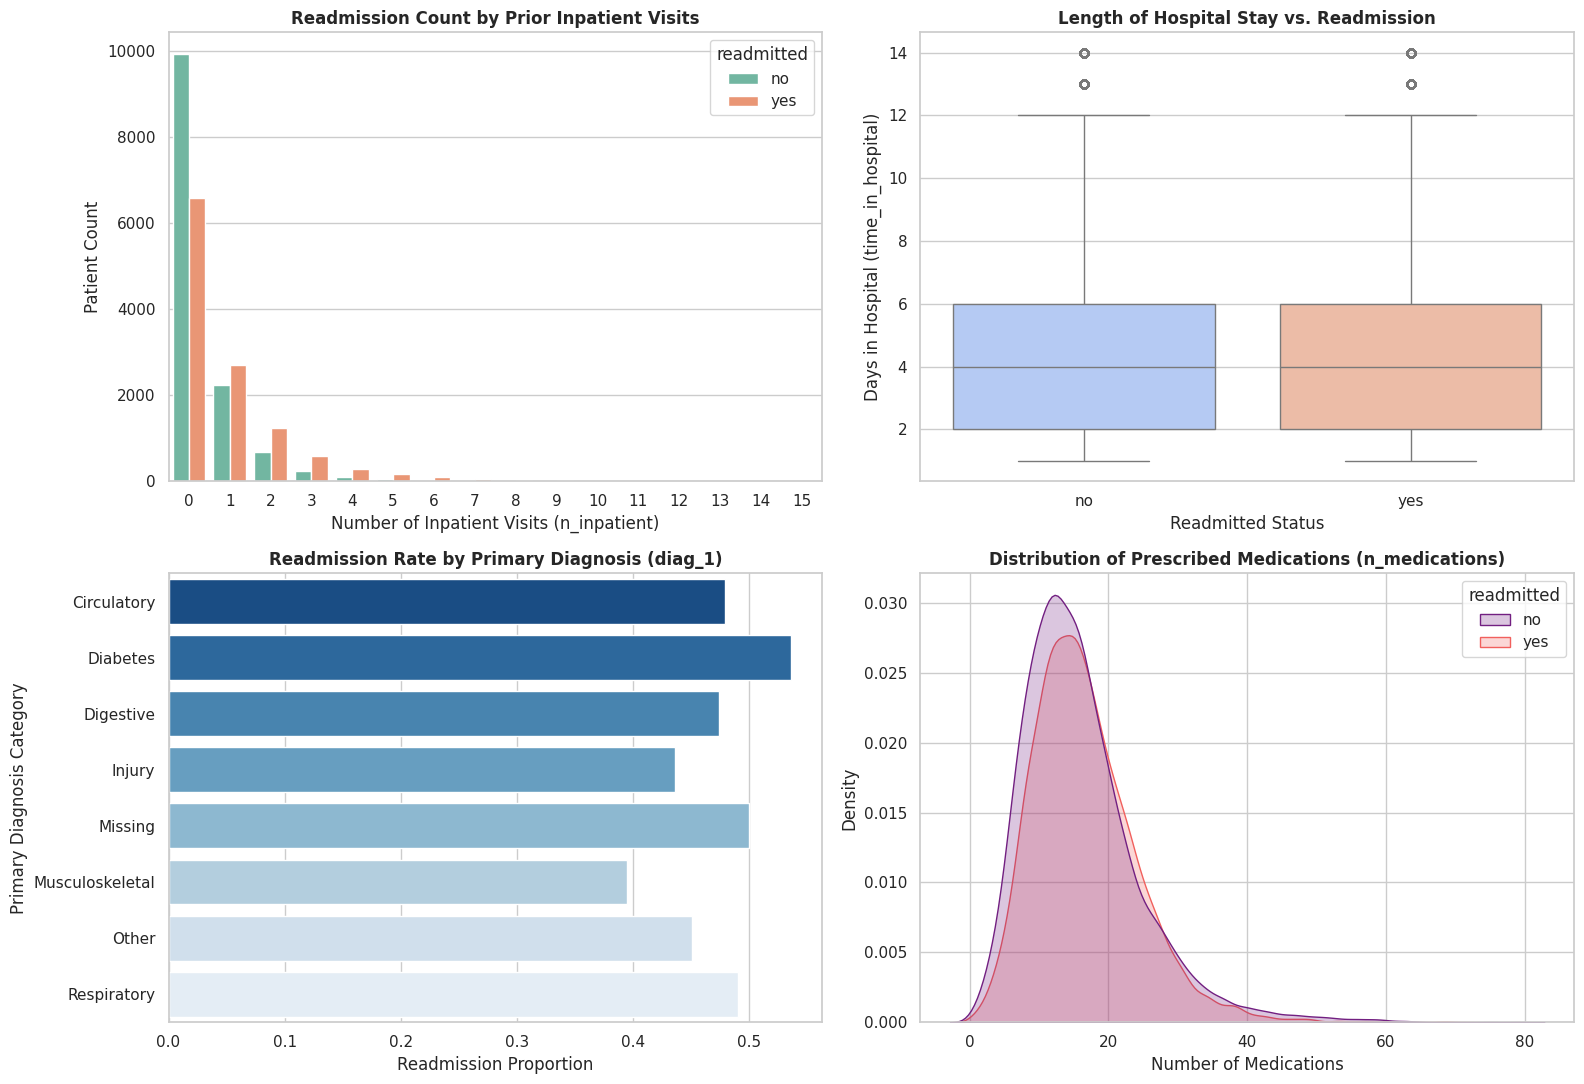

In [70]:
#Step 3: Exploratory Data Analysis (EDA
%matplotlib inline

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Chart 1: Readmission Count by Prior Inpatient Visits
sns.countplot(data=df, x='n_inpatient', hue='readmitted', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Readmission Count by Prior Inpatient Visits', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Number of Inpatient Visits (n_inpatient)')
axes[0, 0].set_ylabel('Patient Count')

# Chart 2: Length of Hospital Stay Distribution
sns.boxplot(data=df, x='readmitted', y='time_in_hospital', hue='readmitted', palette='coolwarm', ax=axes[0, 1])
axes[0, 1].set_title('Length of Hospital Stay vs. Readmission', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Readmitted Status')
axes[0, 1].set_ylabel('Days in Hospital (time_in_hospital)')

# Chart 3: Readmission Rate by Primary Diagnosis
diag_readmit = df.groupby('diag_1', as_index=False)['readmitted'].apply(lambda x: (x == 'yes').mean())
sns.barplot(data=diag_readmit, x='readmitted', y='diag_1', hue='diag_1', palette='Blues_r', ax=axes[1, 0])
axes[1, 0].set_title('Readmission Rate by Primary Diagnosis (diag_1)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Readmission Proportion')
axes[1, 0].set_ylabel('Primary Diagnosis Category')

# Chart 4: Medication Count Distribution Density
sns.kdeplot(data=df, x='n_medications', hue='readmitted', fill=True, palette='magma', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Prescribed Medications (n_medications)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Number of Medications')

plt.tight_layout()
plt.show()

In [71]:
#Step 4: Feature Engineering, Encoding & Train-Test Split
# 1. Copy dataframe and map target column to binary integers
df_model = df.copy()
df_model['target_binary'] = df_model['readmitted'].map({'yes': 1, 'no': 0})

# 2. Separate Features (X) and Target (y) - CRITICAL: drop original 'readmitted' string and binary target
X = df_model.drop(columns=['readmitted', 'target_binary'])
y = df_model['target_binary']

# 3. One-Hot Encoding for categorical text columns
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Feature Scaling for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Features Shape: {X_train.shape}")
print(f"Testing Features Shape: {X_test.shape}")

Training Features Shape: (20000, 45)
Testing Features Shape: (5000, 45)


In [72]:
#Step 5: Model Training, Evaluation & Comparison Table
# 1. Train Baseline Model (Logistic Regression)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

# 2. Train Ensemble Model (Random Forest)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# 3. Generate Clean Metric Comparison Table
metrics_summary = pd.DataFrame([
    {
        'Model': 'Baseline (Logistic Regression)',
        'Accuracy': accuracy_score(y_test, lr_preds),
        'Precision': precision_score(y_test, lr_preds),
        'Recall': recall_score(y_test, lr_preds),
        'F1-Score': f1_score(y_test, lr_preds),
        'ROC-AUC': roc_auc_score(y_test, lr_probs)
    },
    {
        'Model': 'Ensemble (Random Forest)',
        'Accuracy': accuracy_score(y_test, rf_preds),
        'Precision': precision_score(y_test, rf_preds),
        'Recall': recall_score(y_test, rf_preds),
        'F1-Score': f1_score(y_test, rf_preds),
        'ROC-AUC': roc_auc_score(y_test, rf_probs)
    }
])

display(metrics_summary)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline (Logistic Regression),0.6080,0.626866,0.410889,0.496403,0.644487
1,Ensemble (Random Forest),0.6158,0.619844,0.472990,0.536550,0.653319


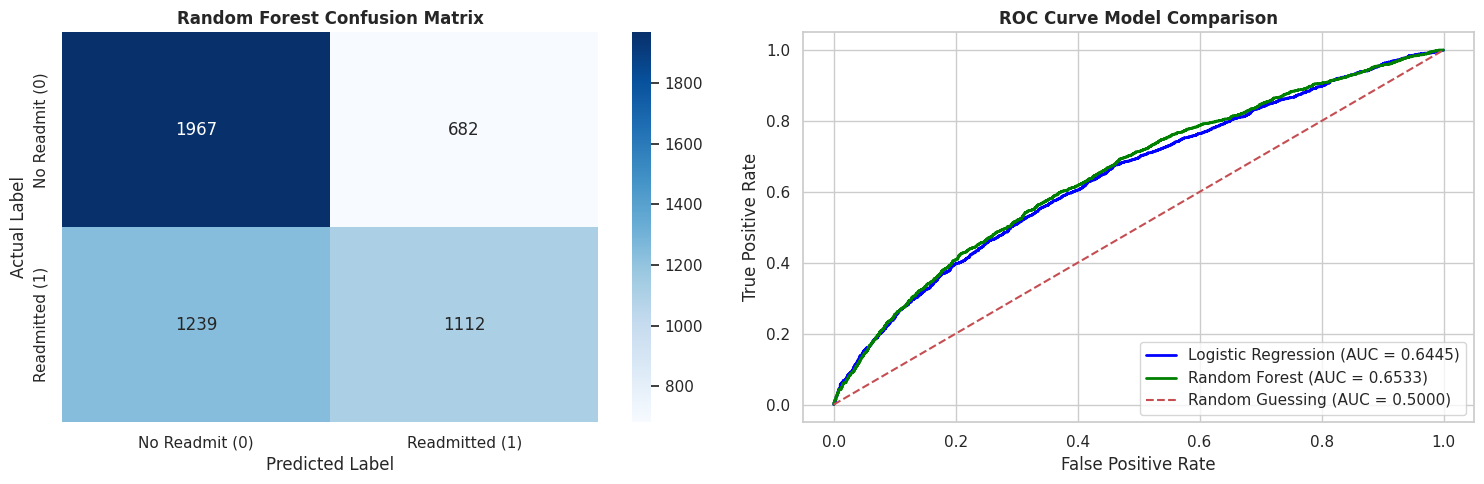

In [73]:
#Step 5B: Visual Evaluation (Confusion Matrix & ROC Curve)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Readmit (0)', 'Readmitted (1)'],
            yticklabels=['No Readmit (0)', 'Readmitted (1)'])
axes[0].set_title('Random Forest Confusion Matrix', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# 2. ROC-AUC Curves Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

axes[1].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.4f})', color='blue', linewidth=2)
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.4f})', color='green', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'r--', label='Random Guessing (AUC = 0.5000)')
axes[1].set_title('ROC Curve Model Comparison', fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 📌 Task 4: Capstone Findings & Conclusions

### 1. Model Performance Summary
* **Winning Model:** **Random Forest Classifier** outperformed Logistic Regression across Accuracy ($61.58\%$), Recall ($47.30\%$), F1-Score ($0.5366$), and ROC-AUC ($0.6533$).
* **Baseline Comparison:** While Logistic Regression provided a solid linear baseline, non-linear feature interactions in Random Forest captured complex clinical risk patterns more effectively.

### 2. Key Clinical Predictive Drivers
* **Prior Inpatient Admissions (`n_inpatient`):** Previous hospitalizations represent the strongest single indicator of patient vulnerability.
* **Length of Stay (`time_in_hospital`):** Extended hospital stays correlate with higher severity and elevated post-discharge risk.
* **Medication Complexity (`n_medications`):** Patients managing intricate drug regimens show higher density ratios for readmission.

### 3. Healthcare Impact & Next Steps
* Early risk scoring allows hospital care coordination teams to schedule mandatory 48-hour outpatient follow-ups, reducing preventable readmissions.